# **Entrenamiento del Modelo IA de Predicción de Abandono (CHURN) v2**
Usa los datos generados por `DataPrepare.ipynb` (carpeta `Data/`).

**Pasos**
1. Carga de los conjuntos train / validación / test
2. Métricas de evaluación
3. Modelos candidatos: baseline, regresión logística, Random Forest y Gradient Boosting
4. Entrenamiento con validación cruzada por cliente + calibración de probabilidades
5. Selección del modelo y resultados en test
6. Calibración, importancia de variables e interpretación
7. Validación externa en CDNOW
8. Sensibilidad a la ventana de predicción
9. Criterios de aceptación
10. Exportar el modelo para la API
11. Pruebas con clientes de ejemplo

> **Por qué no se busca 100 % de precisión:** en la literatura de abandono en comercio no contractual, un ROC-AUC entre 0,70 y 0,85 es un buen resultado. Un valor cercano a 1,0 indica casi siempre **fuga de datos**, que fue el error del modelo v1.

## **1. Cargar los datos preparados**

In [1]:
import json, platform, warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from features import FEATURES          # misma lista de variables que usa la API

warnings.filterwarnings("ignore", message="Unknown solver options")
SEED = 42
VERSION = "2.0.0"                      # cambiar en cada reentrenamiento (p. ej. "2.1.0")
DATA = Path("Data")
MODELOS = Path("modelos")

info = json.loads((DATA / "info_preparacion.json").read_text(encoding="utf-8"))
VENTANA = info["ventana_prediccion_dias"]
datos = pd.read_csv(DATA / f"churn_conjuntos_v{VENTANA}.csv", dtype={"cliente_id": str}, parse_dates=["fecha_corte"])

train, valid, test = (datos[datos.conjunto == c] for c in ("train", "valid", "test"))
X_train, y_train, grupos = train[FEATURES], train["churn"], train["cliente_id"]
X_valid, y_valid = valid[FEATURES], valid["churn"]
X_test, y_test = test[FEATURES], test["churn"]

print(info["definicion_etiqueta"])
pd.DataFrame({"filas": [len(train), len(valid), len(test)],
              "% abandono": [y_train.mean(), y_valid.mean(), y_test.mean()]},
             index=["train", "validación", "test"]).round(3)

churn = 1 si el cliente, con >=1 compra en los 365 días previos al corte, NO compra en los 90 días siguientes al corte


,filas,% abandono
train,15631,0.661
validación,3969,0.639
test,3947,0.508


## **2. Métricas de evaluación**
| Métrica | Qué mide | Referencia |
|---|---|---|
| **ROC-AUC** | Capacidad de ordenar: ¿los que abandonan reciben más riesgo que los que se quedan? | 0,5 = azar |
| **PR-AUC** | Precisión al identificar a los que abandonan | = % de abandono (azar) |
| **Brier** | Error de las probabilidades (la app **muestra** probabilidades) | Brier de predecir siempre el promedio |
| **Lift decil superior** | Cuántas veces más abandonos hay en el 10 % de mayor riesgo que en el total | 1 = azar |
| Precisión / Recall / F1 | Con los umbrales de la app: **0,50** (riesgo medio) y **0,65** (riesgo alto) | — |

Los intervalos de confianza del 95 % se calculan por *bootstrap*.

In [2]:
UMBRALES = {"medio": 0.50, "alto": 0.65}

def metricas(y, p):
    y, p = np.asarray(y).astype(int), np.asarray(p, dtype=float)
    top = np.argsort(-p)[: max(1, len(p) // 10)]
    m = {"n": int(len(y)), "prevalencia": float(y.mean()), "prob_media": float(p.mean()),
         "roc_auc": float(roc_auc_score(y, p)), "pr_auc": float(average_precision_score(y, p)),
         "brier": float(brier_score_loss(y, p)),
         "brier_baseline": float(brier_score_loss(y, np.full_like(p, y.mean()))),
         "lift_decil_superior": float(y[top].mean() / y.mean())}
    for u in UMBRALES.values():
        yhat = (p >= u).astype(int)
        m[f"umbral_{u:.2f}"] = {"precision": float(precision_score(y, yhat, zero_division=0)),
                                "recall": float(recall_score(y, yhat, zero_division=0)),
                                "f1": float(f1_score(y, yhat, zero_division=0)),
                                "matriz_confusion": confusion_matrix(y, yhat, labels=[0, 1]).tolist(),
                                "pct_marcados": float(yhat.mean())}
    return m

def intervalos_bootstrap(y, p, n=300, seed=SEED):
    y, p = np.asarray(y).astype(int), np.asarray(p, dtype=float)
    rng, res = np.random.RandomState(seed), {"roc_auc": [], "pr_auc": [], "brier": []}
    for _ in range(n):
        i = rng.randint(0, len(y), len(y))
        res["roc_auc"].append(roc_auc_score(y[i], p[i]))
        res["pr_auc"].append(average_precision_score(y[i], p[i]))
        res["brier"].append(brier_score_loss(y[i], p[i]))
    return {k: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] for k, v in res.items()}

## **3. Modelos candidatos**
- **Baseline de recencia:** regresión logística con **una sola variable**, los días sin comprar. Es lo que en la práctica hacía el modelo v1. El modelo nuevo debe superarlo.
- **Regresión logística:** interpretable. Las variables de conteo y días se transforman con `log1p` y se estandarizan.
- **Random Forest** y **HistGradientBoosting:** modelos de árboles que capturan relaciones no lineales.

Todos usan `class_weight="balanced"` para el desbalance. Los hiperparámetros se eligen con `GridSearchCV` y **`GroupKFold` por cliente**: el mismo cliente nunca queda a la vez en entrenamiento y en evaluación.

In [3]:
COLS_LOG = ["recencia_dias", "frecuencia", "antiguedad_dias", "compras_por_mes", "compras_30d",
            "compras_90d", "intercompra_media", "ratio_recencia"]
log1p = lambda: FunctionTransformer(np.log1p, feature_names_out="one-to-one")

candidatos = {
    "baseline_recencia": (
        Pipeline([("sel", ColumnTransformer([("log", log1p(), ["recencia_dias"])], remainder="drop")),
                  ("clf", LogisticRegression(max_iter=1000))]),
        {}),
    "regresion_logistica": (
        Pipeline([("log", ColumnTransformer([("log", log1p(), COLS_LOG)], remainder="passthrough",
                                            verbose_feature_names_out=False)),
                  ("sc", StandardScaler()),
                  ("clf", LogisticRegression(class_weight="balanced", max_iter=3000))]),
        {"clf__C": [0.01, 0.1, 1.0, 10.0]}),
    "random_forest": (
        Pipeline([("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                 random_state=SEED, n_jobs=-1))]),
        {"clf__max_depth": [6, 10, None], "clf__min_samples_leaf": [20, 50, 100]}),
    "hist_gradient_boosting": (
        Pipeline([("clf", HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED,
                                                         early_stopping=False, max_iter=300))]),
        {"clf__learning_rate": [0.03, 0.1], "clf__max_leaf_nodes": [15, 31], "clf__l2_regularization": [0.0, 1.0]}),
}

## **4. Entrenamiento y calibración**
1. Búsqueda de hiperparámetros sobre **train**, optimizando PR-AUC.
2. **Calibración sigmoide** sobre el corte de **validación**: convierte el puntaje del modelo en una probabilidad interpretable ("65 de cada 100 clientes con este puntaje no vuelven en 90 días"). `FrozenEstimator` evita reentrenar el modelo al calibrar.
3. Evaluación en validación (para elegir) y en test (para reportar).

⏱️ Tarda unos 2 a 3 minutos.

In [4]:
resultados, modelos, prob_test = {}, {}, {}
for nombre, (pipe, grid) in candidatos.items():
    if grid:
        busqueda = GridSearchCV(pipe, grid, scoring="average_precision", cv=GroupKFold(n_splits=5), n_jobs=-1)
        busqueda.fit(X_train, y_train, groups=grupos)
        base, params = busqueda.best_estimator_, busqueda.best_params_
    else:
        base, params = pipe.fit(X_train, y_train), {}
    calibrado = CalibratedClassifierCV(FrozenEstimator(base), method="sigmoid").fit(X_valid, y_valid)
    modelos[nombre] = calibrado
    prob_test[nombre] = calibrado.predict_proba(X_test)[:, 1]
    resultados[nombre] = {
        "mejores_parametros": {k: (v.item() if hasattr(v, "item") else v) for k, v in params.items()},
        "validacion": metricas(y_valid, calibrado.predict_proba(X_valid)[:, 1]),
        "test": metricas(y_test, prob_test[nombre]),
        "test_ic95": intervalos_bootstrap(y_test, prob_test[nombre]),
    }
    print(f"✔ {nombre:24s} {params}")

tabla = pd.DataFrame({n: {"PR-AUC valid": r["validacion"]["pr_auc"], "ROC-AUC test": r["test"]["roc_auc"],
                          "PR-AUC test": r["test"]["pr_auc"], "Brier test": r["test"]["brier"],
                          "Brier referencia": r["test"]["brier_baseline"], "Lift decil": r["test"]["lift_decil_superior"]}
                      for n, r in resultados.items()}).T
tabla.round(3)

✔ baseline_recencia        {}
✔ regresion_logistica      {'clf__C': 0.01}
✔ random_forest            {'clf__max_depth': None, 'clf__min_samples_leaf': 100}


C:\Users\Sr. Sebastian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Sr. Sebastian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\joblib\externals\loky\backend\context.py", line 282, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


✔ hist_gradient_boosting   {'clf__l2_regularization': 0.0, 'clf__learning_rate': 0.03, 'clf__max_leaf_nodes': 15}


,PR-AUC valid,ROC-AUC test,PR-AUC test,Brier test,Brier referencia,Lift decil
baseline_recencia,0.822,0.707,0.682,0.241,0.25,1.454
regresion_logistica,0.850,0.768,0.736,0.214,0.25,1.604
random_forest,0.846,0.768,0.738,0.209,0.25,1.604
hist_gradient_boosting,0.844,0.765,0.732,0.210,0.25,1.594


## **5. Selección del modelo y resultados en test**
Se elige el candidato (sin contar el baseline) con **mayor PR-AUC en validación**. El conjunto de test **no** participa en la elección.

Modelo elegido: regresion_logistica  (mejora de PR-AUC sobre el baseline en validación: +0.028)

  roc_auc  test = 0.768   IC95% [0.753 – 0.782]
  pr_auc   test = 0.736   IC95% [0.715 – 0.758]
  brier    test = 0.214   IC95% [0.207 – 0.221]
  Brier de referencia (predecir siempre 0.51) = 0.250
  Lift decil superior = 1.60 (máximo posible 1.97)


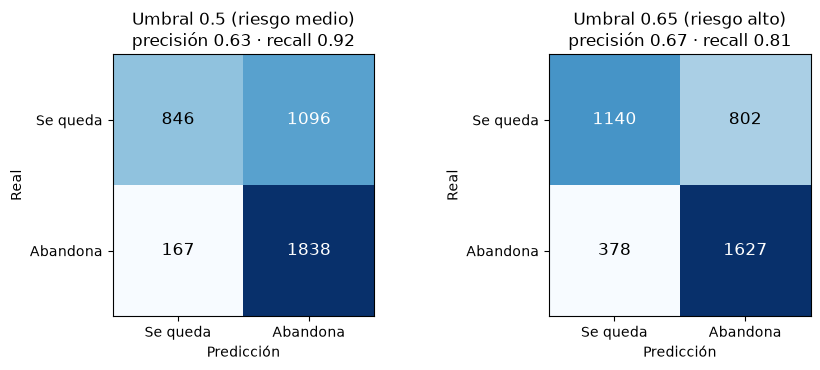

In [5]:
CAMPEON = max([n for n in resultados if n != "baseline_recencia"], key=lambda n: resultados[n]["validacion"]["pr_auc"])
modelo = modelos[CAMPEON]
r = resultados[CAMPEON]
mejora = r["validacion"]["pr_auc"] - resultados["baseline_recencia"]["validacion"]["pr_auc"]
print(f"Modelo elegido: {CAMPEON}  (mejora de PR-AUC sobre el baseline en validación: {mejora:+.3f})\n")
for k in ("roc_auc", "pr_auc", "brier"):
    lo, hi = r["test_ic95"][k]
    print(f"  {k:8s} test = {r['test'][k]:.3f}   IC95% [{lo:.3f} – {hi:.3f}]")
print(f"  Brier de referencia (predecir siempre {r['test']['prevalencia']:.2f}) = {r['test']['brier_baseline']:.3f}")
print(f"  Lift decil superior = {r['test']['lift_decil_superior']:.2f} (máximo posible {1 / r['test']['prevalencia']:.2f})")

fig, ejes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (nivel, u) in zip(ejes, UMBRALES.items()):
    mc = np.array(r["test"][f"umbral_{u:.2f}"]["matriz_confusion"])
    ax.imshow(mc, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, mc[i, j], ha="center", va="center", fontsize=12,
                    color="white" if mc[i, j] > mc.max() / 2 else "black")
    ax.set_xticks([0, 1], ["Se queda", "Abandona"]); ax.set_yticks([0, 1], ["Se queda", "Abandona"])
    ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
    m = r["test"][f"umbral_{u:.2f}"]
    ax.set_title(f"Umbral {u} (riesgo {nivel})\nprecisión {m['precision']:.2f} · recall {m['recall']:.2f}")
plt.tight_layout(); plt.show()

**Cómo leer la matriz:** con el umbral 0,65, de cada 100 clientes que el CRM marca como "riesgo alto", unos 67 realmente no vuelven en 90 días. Además, el CRM detecta a 8 de cada 10 de los que abandonan. Para una MiPyME esto significa **priorizar llamadas o visitas** con una lista mucho mejor que el azar.

## **6. Calibración, importancia de variables e interpretación**

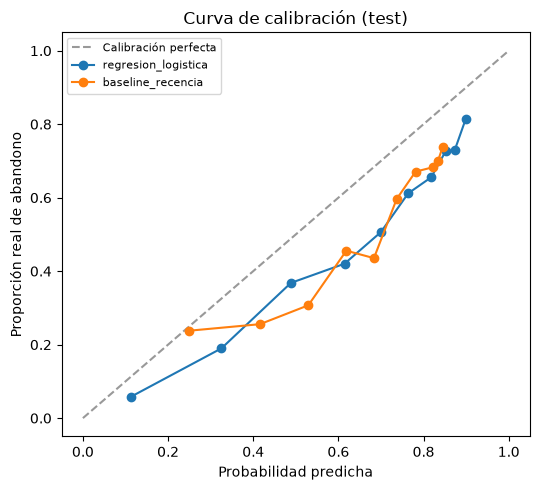

Probabilidad media predicha 0.645 vs abandono real 0.508


In [6]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], "--", color="#999", label="Calibración perfecta")
for n in (CAMPEON, "baseline_recencia"):
    real, pred = calibration_curve(y_test, prob_test[n], n_bins=10, strategy="quantile")
    ax.plot(pred, real, marker="o", label=n)
ax.set_xlabel("Probabilidad predicha"); ax.set_ylabel("Proporción real de abandono")
ax.set_title("Curva de calibración (test)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print(f"Probabilidad media predicha {r['test']['prob_media']:.3f} vs abandono real {r['test']['prevalencia']:.3f}")

**Interpretación:** la curva queda por debajo de la diagonal. El modelo **sobreestima** el riesgo unos 14 puntos en el corte de test, porque ese periodo (septiembre a noviembre, temporada navideña) tiene menos abandono que los periodos con los que se entrenó y calibró. El **orden** de los clientes sí es confiable, como muestran el ROC-AUC y el PR-AUC. En producción esto se corrige **recalibrando** con el periodo más reciente (comando `flask churn-recalibrate`).

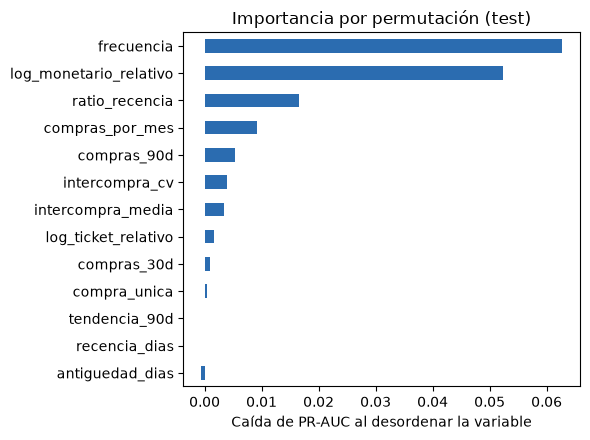

,"coeficiente (+ sube el riesgo, − lo baja)"
frecuencia,-0.645
log_monetario_relativo,-0.442
ratio_recencia,0.183
compras_por_mes,-0.158
compras_90d,-0.134
intercompra_cv,0.114
compras_30d,-0.071
intercompra_media,0.055
tendencia_90d,0.049
log_ticket_relativo,0.046


In [7]:
imp = permutation_importance(modelo, X_test, y_test, scoring="average_precision", n_repeats=5,
                             random_state=SEED, n_jobs=-1)
importancias = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
importancias.plot.barh(figsize=(6, 4.5), color="#2b6cb0", title="Importancia por permutación (test)")
plt.xlabel("Caída de PR-AUC al desordenar la variable"); plt.tight_layout(); plt.show()

if CAMPEON == "regresion_logistica":
    pipe = modelo.calibrated_classifiers_[0].estimator.estimator
    coef = pd.Series(pipe[-1].coef_[0], index=pipe[:-1].get_feature_names_out()).sort_values(key=abs, ascending=False)
    display(coef.round(3).to_frame("coeficiente (+ sube el riesgo, − lo baja)"))

**Lectura de negocio:** más compras y más gasto **bajan** el riesgo. Llevar más tiempo sin comprar del habitual para ese cliente (`ratio_recencia`) y comprar de forma irregular lo **suben**. Son las razones que la API muestra al dueño de la tienda.

## **7. Validación externa en CDNOW**
Se aplica el modelo **sin reentrenar** a otro negocio:
- **Sin recalibrar:** ¿se mantiene el ordenamiento de los clientes?
- **Recalibrado:** se ajusta la probabilidad con un corte local antiguo (1998-01) y se mide en uno posterior (1998-04). Es el procedimiento previsto para el piloto en Santander de Quilichao.

In [8]:
cd_cal = pd.read_csv(DATA / "cdnow_recalibracion.csv", dtype={"cliente_id": str})
cd_test = pd.read_csv(DATA / "cdnow_test.csv", dtype={"cliente_id": str})
recal = CalibratedClassifierCV(FrozenEstimator(modelo), method="sigmoid").fit(cd_cal[FEATURES], cd_cal["churn"])
externa = {"corte_recalibracion": "1998-01-01", "corte_test": "1998-04-01",
           "sin_recalibrar": metricas(cd_test["churn"], modelo.predict_proba(cd_test[FEATURES])[:, 1]),
           "recalibrado": metricas(cd_test["churn"], recal.predict_proba(cd_test[FEATURES])[:, 1])}
pd.DataFrame({k: {m: externa[k][m] for m in ("prevalencia", "prob_media", "roc_auc", "pr_auc", "brier", "brier_baseline")}
              for k in ("sin_recalibrar", "recalibrado")}).round(3)

,sin_recalibrar,recalibrado
prevalencia,0.702,0.702
prob_media,0.666,0.781
roc_auc,0.739,0.739
pr_auc,0.842,0.842
brier,0.175,0.181
brier_baseline,0.209,0.209


**Resultado:** el ordenamiento se transfiere a otro negocio (ROC-AUC ≈ 0,74 sin reentrenar), y el Brier es mejor que la referencia. La recalibración con un corte **antiguo** no mejoró, porque la tasa de abandono cambió entre enero y abril. Lección para el piloto: recalibrar siempre con el periodo cumplido **más reciente**, y aceptar la recalibración solo si el Brier mejora.

## **8. Sensibilidad a la ventana de predicción**
Mismo modelo y mismos hiperparámetros, con ventanas de 60, 90 y 120 días.

In [9]:
sens = {}
for v in (60, 90, 120):
    d = datos if v == VENTANA else pd.read_csv(DATA / f"churn_conjuntos_v{v}.csv", dtype={"cliente_id": str})
    tr, va, te = (d[d.conjunto == c] for c in ("train", "valid", "test"))
    m = sklearn.base.clone(candidatos[CAMPEON][0]).set_params(**r["mejores_parametros"]).fit(tr[FEATURES], tr["churn"])
    m = CalibratedClassifierCV(FrozenEstimator(m), method="sigmoid").fit(va[FEATURES], va["churn"])
    met = metricas(te["churn"], m.predict_proba(te[FEATURES])[:, 1])
    sens[f"{v}_dias"] = {k: met[k] for k in ("prevalencia", "roc_auc", "pr_auc", "brier", "brier_baseline", "lift_decil_superior")}
pd.DataFrame(sens).T.round(3)

,prevalencia,roc_auc,pr_auc,brier,brier_baseline,lift_decil_superior
60_dias,0.573,0.760,0.778,0.203,0.245,1.460
90_dias,0.508,0.768,0.736,0.214,0.250,1.604
120_dias,0.481,0.785,0.736,0.197,0.250,1.706


El desempeño es estable entre ventanas (ROC-AUC 0,76–0,79). Se mantiene **90 días** por estar justificada por el ritmo de recompra (ver `DataPrepare.ipynb`) y porque da tiempo de actuar.

## **9. Criterios de aceptación**
Un modelo nuevo solo se activa en la API si cumple **todos** los criterios:

In [10]:
criterios = {
    "ROC-AUC test >= 0.70": r["test"]["roc_auc"] >= 0.70,
    "ROC-AUC test <= 0.97 (sin señal de fuga)": r["test"]["roc_auc"] <= 0.97,
    "PR-AUC test > % de abandono": r["test"]["pr_auc"] > r["test"]["prevalencia"],
    "Brier test < Brier de referencia": r["test"]["brier"] < r["test"]["brier_baseline"],
    "Supera al baseline de recencia (validación)": mejora > 0,
}
for k, ok in criterios.items():
    print(("✔ " if ok else "✘ ") + k)
ACEPTADO = all(criterios.values())
print("\nMODELO ACEPTADO" if ACEPTADO else "\nMODELO RECHAZADO: no se activará")

✔ ROC-AUC test >= 0.70
✔ ROC-AUC test <= 0.97 (sin señal de fuga)
✔ PR-AUC test > % de abandono
✔ Brier test < Brier de referencia
✔ Supera al baseline de recencia (validación)

MODELO ACEPTADO


## **10. Exportar el modelo para la API**
Se guarda en `modelos/v<VERSION>/`:
- `modelo.pkl`: modelo calibrado, lista de variables, umbrales y distribuciones de referencia para el monitoreo (PSI).
- `metricas.json`: todos los resultados de este notebook.
- Gráficos de calibración e importancia.

Si el modelo fue **aceptado**, `modelos/ACTUAL` pasa a apuntar a esta versión, y la API la usa desde la siguiente predicción sin reiniciar.

In [11]:
def referencia_psi(valores, n_bins=10):
    v = np.asarray(pd.Series(valores).dropna(), dtype=float)
    cortes = np.unique(np.quantile(v, np.linspace(0, 1, n_bins + 1)[1:-1]))
    props = np.bincount(np.searchsorted(cortes, v, side="right"), minlength=len(cortes) + 1) / len(v)
    return {"cortes": cortes.tolist(), "proporciones": props.tolist()}

salida = MODELOS / f"v{VERSION}"
salida.mkdir(parents=True, exist_ok=True)

referencias = {c: referencia_psi(X_train[c]) for c in FEATURES}
referencias["probabilidad"] = referencia_psi(prob_test[CAMPEON])
joblib.dump({"modelo": modelo, "features": FEATURES, "version": VERSION, "campeon": CAMPEON,
             "ventana_prediccion_dias": VENTANA, "ventana_observacion_dias": info["ventana_observacion_dias"],
             "umbrales": UMBRALES, "referencias_psi": referencias, "scikit_learn": sklearn.__version__},
            salida / "modelo.pkl", compress=3)

# Gráficos para la tesis
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], "--", color="#999", label="Calibración perfecta")
for n in (CAMPEON, "baseline_recencia"):
    real, pred = calibration_curve(y_test, prob_test[n], n_bins=10, strategy="quantile")
    ax.plot(pred, real, marker="o", label=n)
ax.set_xlabel("Probabilidad predicha"); ax.set_ylabel("Proporción real de abandono")
ax.set_title("Curva de calibración (test)"); ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(salida / "calibracion_test.png", dpi=130); plt.close(fig)
fig, ax = plt.subplots(figsize=(6, 4.5))
importancias.plot.barh(ax=ax, color="#2b6cb0", title="Importancia por permutación (test)")
ax.set_xlabel("Caída de PR-AUC al desordenar la variable"); fig.tight_layout()
fig.savefig(salida / "importancia_permutacion.png", dpi=130); plt.close(fig)

metricas_json = {
    "version": VERSION, "fecha_entrenamiento": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "fuente": "online_retail_ii", "ventana_prediccion_dias": VENTANA,
    "ventana_observacion_dias": info["ventana_observacion_dias"], "definicion_etiqueta": info["definicion_etiqueta"],
    "cortes": info["cortes"], "filas": {"train": len(train), "valid": len(valid), "test": len(test)},
    "prevalencia": {"train": float(y_train.mean()), "valid": float(y_valid.mean()), "test": float(y_test.mean())},
    "features": FEATURES, "campeon": CAMPEON, "resultados": resultados,
    "importancia_permutacion_test": importancias.sort_values(ascending=False).round(4).to_dict(),
    "criterios_aceptacion": criterios, "aceptado": ACEPTADO,
    "validacion_externa_cdnow": externa, "sensibilidad_ventana": sens,
    "auditoria_v1": info["auditoria_v1"],
    "entorno": {"python": platform.python_version(), "scikit_learn": sklearn.__version__,
                "pandas": pd.__version__, "numpy": np.__version__, "semilla": SEED},
}
(salida / "metricas.json").write_text(json.dumps(metricas_json, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

if ACEPTADO:
    (MODELOS / "ACTUAL").write_text(f"v{VERSION}\n", encoding="utf-8")
    print(f"✔ Modelo guardado en {salida} y activado (modelos/ACTUAL = v{VERSION})")
else:
    print(f"✘ Modelo guardado en {salida} pero NO activado")

✔ Modelo guardado en modelos\v2.0.0 y activado (modelos/ACTUAL = v2.0.0)


## **11. Pruebas con clientes de ejemplo**
Igual que en el notebook del modelo v1: se generan clientes con distintos comportamientos y se calcula su riesgo con **la misma función de variables que usa la API**.

In [12]:
from features import construir_features

hoy = pd.Timestamp("2026-10-01")
perfiles = {                      # (nº compras, días entre compras, días desde la última compra)
    "Cliente fiel (cada 20 días)": (15, 20, 3),
    "Cliente en pausa":            (6, 45, 100),
    "Cliente perdido":             (4, 30, 300),
    "Una sola compra":             (1, 0, 40),
}
filas = []
for nombre, (n, gap, ultima) in perfiles.items():
    for k in range(n):
        filas.append({"cliente_id": nombre, "factura_id": f"{nombre}{k}", "tienda_id": "tienda_demo",
                      "fecha": hoy - pd.Timedelta(days=ultima + gap * (n - 1 - k)), "monto": 35000})
X_demo = construir_features(pd.DataFrame(filas), hoy)
p = modelo.predict_proba(X_demo[FEATURES])[:, 1]
nivel = np.where(p >= UMBRALES["alto"], "alto", np.where(p >= UMBRALES["medio"], "medio", "bajo"))
pd.DataFrame({"probabilidad de abandono": p.round(3), "nivel": nivel,
              "días sin comprar": X_demo["recencia_dias"].round(0),
              "veces su ritmo habitual": X_demo["ratio_recencia"].round(1)}, index=X_demo.index)

,probabilidad de abandono,nivel,días sin comprar,veces su ritmo habitual
cliente_id,,,,
Cliente en pausa,0.466,bajo,100.0,2.2
Cliente fiel (cada 20 días),0.073,bajo,3.0,0.2
Cliente perdido,0.767,alto,300.0,10.0
Una sola compra,0.845,alto,40.0,0.1
